# Multilingual GPT-2: from implementation to inference

A custom GPT-2 transformer and AdamW optimizer, fine-tuned for natural language inference. Given a **premise** and **hypothesis**, the model generates one of three labels: entailment, contradiction, or neutral.

This notebook presents saved results. Training, datasets, model code, and analysis live in the `multilingual_gpt2` Python package; running these cells does not download weights or retrain models.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

from multilingual_gpt2.reporting import (
    load_result,
    plot_learning_curve,
    prediction_examples,
    run_summary,
)

root = Path.cwd()
runs = [
    load_result(path)
    for path in sorted(root.glob("results/showcase*/results.json"))
]
assert runs, "Run the showcase command in README.md first."

## Verified local experiments

These are newly measured subset runs, not a reproduction of the full-data PDF benchmark. Development accuracy selects the checkpoint; test examples are held out from training. Both early and larger runs remain visible. The majority baseline predicts the most common test label.

In [2]:
display(run_summary(runs))

,training examples,test examples,test accuracy (%),majority baseline (%),valid labels (%),selected epoch
0,1024,256,32.81,34.38,100.0,1
1,8192,512,70.70,33.98,100.0,1


The larger run trained on 8,192 examples and reaches **70.7% test accuracy on 512 examples**, with 72.1% development accuracy. The first 1,024-example run reaches 32.8% test accuracy, below its 34.4% majority baseline. Both verify the workflow; only the larger run demonstrates useful subset performance. Full-data reproduction remains pending.

In [3]:
selected = max(runs, key=lambda run: run["settings"]["train_count"])
display(
    pd.Series(
        {
            key: selected["settings"][key]
            for key in (
                "model",
                "initialization",
                "train_count",
                "dev_count",
                "test_count",
                "seed",
                "max_length",
                "epochs",
                "batch_size",
                "lr",
                "gpu",
                "torch",
            )
        }
    ).to_frame("run settings")
)

,run settings
model,artifacts/gpt2
initialization,pretrained
train_count,8192
dev_count,512
test_count,512
seed,42
max_length,128
epochs,1
batch_size,4
lr,0.00005


## Learning curve

Loss is computed only on the target label. Prompt and padding positions do not contribute. A falling training loss alone is not evidence of improved held-out accuracy.

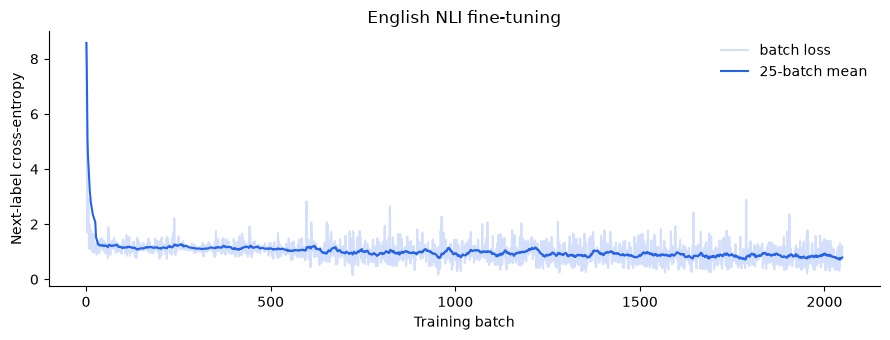

In [4]:
figure = plot_learning_curve(selected)

## Predictions

The first six held-out examples in the recorded evaluation order, including mistakes. No examples are selected by correctness.

In [5]:
pd.set_option("display.max_colwidth", 100)
display(prediction_examples(selected))

,premise,hypothesis,gold,prediction,correct
0,spend it on the ones who who do have a chance,"Give it to everyone, regardless of what they will do with it.",contradiction,contradiction,True
1,"They just didn't like what it was like being black in those days, and that was, you know, I gues...",It was hard to be black in the south.,neutral,neutral,True
2,"Close to the original action and still providing the most vivid testimony to the Klondike days, ...",Whitehorse used mainly horse carriages for transportation.,neutral,neutral,True
3,The museum is not strong on catalogues or labels,The strong point of the museum is the catalogues.,contradiction,entailment,False
4,Levasseur? He smiled a little.,He kept his mouth closed as he smiled a bit.,neutral,contradiction,False
5,"As the Secret Constitution would again reassert itself in American politics, we would also take ...",The Fifteenth Amendment was immediately written off and never passed.,contradiction,contradiction,True


## Historical multilingual results

Transcribed from PDF pages 32-34; **not reproduced by the local showcase**. The original comparison mixes test, development subsets, and full development results, so improvements across these columns are not controlled comparisons. Corrected experiments evaluate all variants on the same held-out split.

Fertility is the number of tokenizer subwords per whitespace-estimated word. It is only an approximate cross-language measure, especially for languages without consistent whitespace word boundaries.

In [6]:
historical = load_result(root / "results/historical.json")
display(pd.DataFrame(historical["rows"]).set_index("language"))

,fertility,zero_shot_test_percent,per_language_dev_percent,combined_dev_percent
language,,,,
en,1.11,78.02,NaN,NaN
ar,4.70,37.09,NaN,NaN
bg,5.53,36.57,NaN,NaN
de,2.10,41.52,63.86,61.45
el,6.16,37.86,NaN,NaN
es,1.83,45.55,63.45,64.58
fr,1.75,40.38,65.86,62.85
hi,5.12,36.71,NaN,NaN
ru,5.90,37.80,NaN,NaN


## Recovered multilingual diagnostics

A small integration check of the 8,192-example checkpoint: **24 held-out examples per language**, eight development embeddings per language, seed 42. These tiny samples demonstrate the recovered analyses; they do not establish language rankings or benchmark quality. Calibration renormalizes probabilities over the three NLI labels. Attention shows the first sampled English development example.

In [7]:
diagnostics = load_result(root / "results/diagnostics/summary.json")
display(
    pd.DataFrame(diagnostics["languages"])[
        ["language", "count", "accuracy", "fertility", "ece", "brier"]
    ].set_index("language")
)

,count,accuracy,fertility,ece,brier
language,,,,,
en,24,0.750000,1.105069,0.159430,0.368230
es,24,0.333333,1.838569,0.238899,0.721364
fr,24,0.541667,1.767685,0.203374,0.630359
de,24,0.458333,2.093640,0.138229,0.609626
sw,24,0.250000,2.088325,0.359612,0.892792


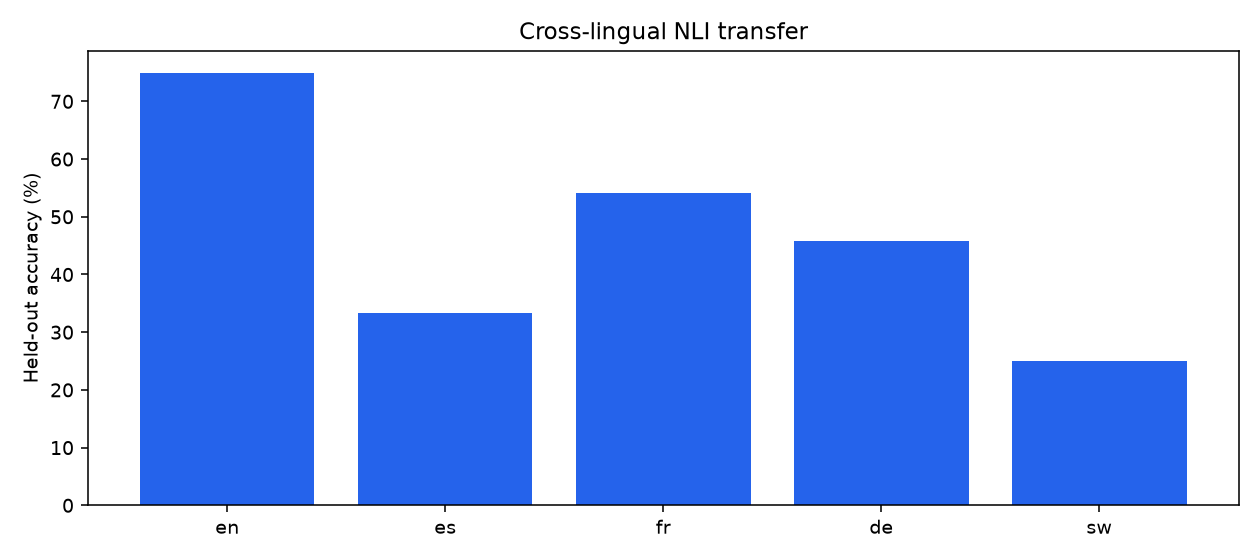

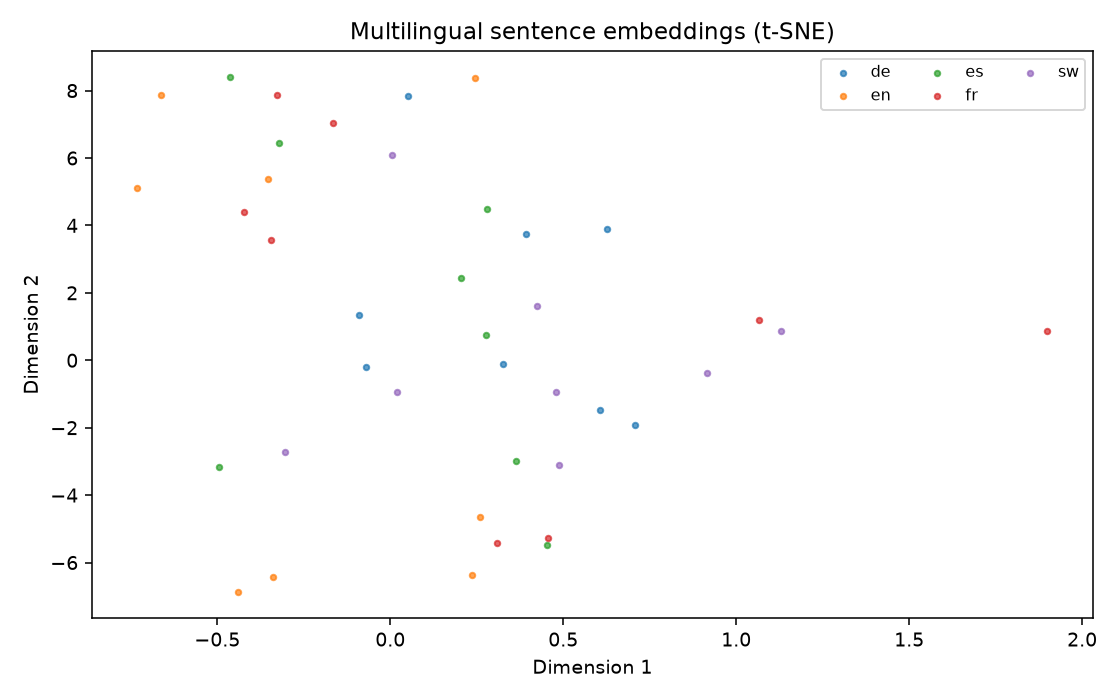

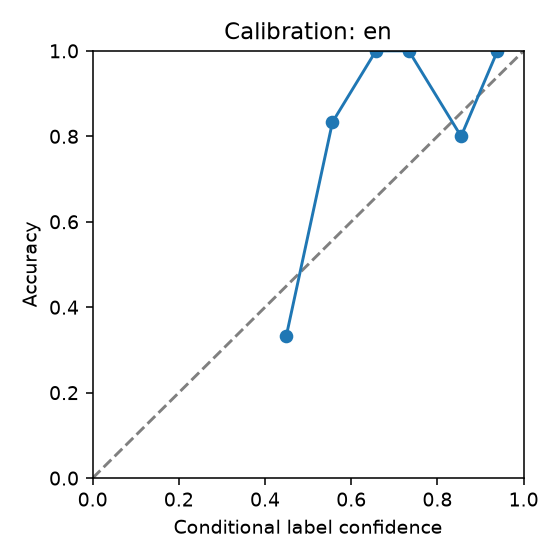

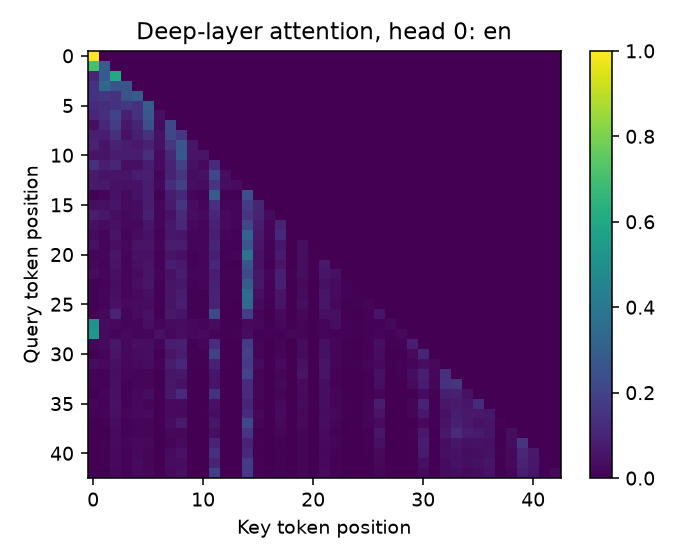

In [8]:
from IPython.display import Image

for name in ("accuracy", "embeddings", "en-calibration", "en-attention"):
    display(Image(filename=str(root / f"results/diagnostics/{name}.png")))

## Sentiment and tone extensions

All three sentiment prompt modes were executed on 12 examples in each of six languages. This NLI checkpoint produced no recognized sentiment labels in these checks: accuracy and coverage are zero. Unknown answers remain in the denominator. This is a measured failure, not evidence that sentiment classification works.

Tone classification, pragmatic NLI, style generation, and cross-language probe evaluation have separate command-line workflows. Their original synthetic datasets are absent. Integration fixtures verify execution only; fixture scores are deliberately omitted here. Dataset generation is an explicit, bounded opt-in command and has not called a paid API.

In [9]:
sentiment = load_result(root / "results/diagnostics/sentiment.json")
display(
    pd.DataFrame(sentiment)[
        ["language", "mode", "count", "accuracy", "macro_f1", "coverage"]
    ].set_index(["language", "mode"])
)

count  accuracy  macro_f1  coverage
language mode                                       
arabic   zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
english  zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
french   zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
german   zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
hindi    zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0
spanish  zero       12       0.0       0.0       0.0
         few        12       0.0       0.0       0.0
         strict     12       0.0       0.0       0.0

## Reconstruction and reproducibility

The original PDF remains unchanged. The [reconstruction log](docs/reconstruction.md) maps every section, documents corrections and verification, and distinguishes completed work from missing data or pending full runs.

The extended work covers multilingual training, sentiment prompting, fertility correlations, embedding and attention analysis, calibration, error annotation, and synthetic tone experiments. The original synthetic JSONL datasets are absent and their historical results cannot yet be reproduced. See [README.md](README.md) for execution commands.

Checks include reference GPT-2 output agreement, the preserved AdamW numerical reference, long-input label retention, checkpoint reload, and full-denominator evaluation.